In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
countries_df = pd.read_csv("Countries Data.csv")
countries = countries_df
countries.head(3)

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710


In [5]:
c_52 = countries.loc[countries['year'] == 1952]
c_52.head()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
12,Albania,1952,1282697,Europe,55.230,1601.056136
24,Algeria,1952,9279525,Africa,43.077,2449.008185
36,Angola,1952,4232095,Africa,30.015,3520.610273
48,Argentina,1952,17876956,Americas,62.485,5911.315053


In [6]:
c_07 = countries.loc[countries['year'] == 2007]
c_07.head()

type(c_52)

pandas.DataFrame

In [7]:
c_merge = c_52.merge(c_07, left_on='country', right_on='country')
c_merge.head()

,country,year_x,population_x,continent_x,life_exp_x,gdp_cap_x,year_y,population_y,continent_y,life_exp_y,gdp_cap_y
0,Afghanistan,1952,8425333,Asia,28.801,779.445314,2007,31889923,Asia,43.828,974.580338
1,Albania,1952,1282697,Europe,55.230,1601.056136,2007,3600523,Europe,76.423,5937.029526
2,Algeria,1952,9279525,Africa,43.077,2449.008185,2007,33333216,Africa,72.301,6223.367465
3,Angola,1952,4232095,Africa,30.015,3520.610273,2007,12420476,Africa,42.731,4797.231267
4,Argentina,1952,17876956,Americas,62.485,5911.315053,2007,40301927,Americas,75.320,12779.379640


In [8]:
c_merge = c_merge.drop(['year_x', 'year_y'], axis=1)
c_merge.head()

,country,population_x,continent_x,life_exp_x,gdp_cap_x,population_y,continent_y,life_exp_y,gdp_cap_y
0,Afghanistan,8425333,Asia,28.801,779.445314,31889923,Asia,43.828,974.580338
1,Albania,1282697,Europe,55.230,1601.056136,3600523,Europe,76.423,5937.029526
2,Algeria,9279525,Africa,43.077,2449.008185,33333216,Africa,72.301,6223.367465
3,Angola,4232095,Africa,30.015,3520.610273,12420476,Africa,42.731,4797.231267
4,Argentina,17876956,Americas,62.485,5911.315053,40301927,Americas,75.320,12779.379640


In [10]:
c_merge['population_growth'] = (
    c_merge['population_y'] - c_merge['population_x']
)

c_merge.head()

,country,population_x,continent_x,life_exp_x,gdp_cap_x,population_y,continent_y,life_exp_y,gdp_cap_y,population_growth
0,Afghanistan,8425333,Asia,28.801,779.445314,31889923,Asia,43.828,974.580338,23464590
1,Albania,1282697,Europe,55.230,1601.056136,3600523,Europe,76.423,5937.029526,2317826
2,Algeria,9279525,Africa,43.077,2449.008185,33333216,Africa,72.301,6223.367465,24053691
3,Angola,4232095,Africa,30.015,3520.610273,12420476,Africa,42.731,4797.231267,8188381
4,Argentina,17876956,Americas,62.485,5911.315053,40301927,Americas,75.320,12779.379640,22424971


In [11]:
31889923 - 8425333

c_merge.shape, type(c_merge)

((142, 10), pandas.DataFrame)

In [12]:
c_merge = c_merge.sort_values(
    'population_growth',
    ascending=False
).head(10)

c_merge.head(10)

,country,population_x,continent_x,life_exp_x,gdp_cap_x,population_y,continent_y,life_exp_y,gdp_cap_y,population_growth
24,China,556263527,Asia,44.000,400.448611,1318683096,Asia,72.961,4959.114854,762419569
58,India,372000000,Asia,37.373,546.565749,1110396331,Asia,64.698,2452.210407,738396331
134,United States,157553000,Americas,68.440,13990.482080,301139947,Americas,78.242,42951.653090,143586947
59,Indonesia,82052000,Asia,37.468,749.681655,223547000,Asia,70.650,3540.651564,141495000
14,Brazil,56602560,Americas,50.917,2108.944355,190010647,Americas,72.390,9065.800825,133408087
97,Pakistan,41346560,Asia,43.436,684.597144,169270617,Asia,65.483,2605.947580,127924057
8,Bangladesh,46886859,Asia,37.484,684.244172,150448339,Asia,64.062,1391.253792,103561480
94,Nigeria,33119096,Africa,36.324,1077.281856,135031164,Africa,46.859,2013.977305,101912068
82,Mexico,30144317,Americas,50.789,3478.125529,108700891,Americas,76.195,11977.574960,78556574
101,Philippines,22438691,Asia,47.752,1272.880995,91077287,Asia,71.688,3190.481016,68638596


In [13]:
c_merge = c_merge.reset_index()

c_merge.head(10)

c_merge.shape

(10, 11)

In [14]:
c_merge = c_merge.drop(['index'], axis=1)

c_merge.shape

(10, 10)

In [15]:
c_merge

,country,population_x,continent_x,life_exp_x,gdp_cap_x,population_y,continent_y,life_exp_y,gdp_cap_y,population_growth
0,China,556263527,Asia,44.000,400.448611,1318683096,Asia,72.961,4959.114854,762419569
1,India,372000000,Asia,37.373,546.565749,1110396331,Asia,64.698,2452.210407,738396331
2,United States,157553000,Americas,68.440,13990.482080,301139947,Americas,78.242,42951.653090,143586947
3,Indonesia,82052000,Asia,37.468,749.681655,223547000,Asia,70.650,3540.651564,141495000
4,Brazil,56602560,Americas,50.917,2108.944355,190010647,Americas,72.390,9065.800825,133408087
5,Pakistan,41346560,Asia,43.436,684.597144,169270617,Asia,65.483,2605.947580,127924057
6,Bangladesh,46886859,Asia,37.484,684.244172,150448339,Asia,64.062,1391.253792,103561480
7,Nigeria,33119096,Africa,36.324,1077.281856,135031164,Africa,46.859,2013.977305,101912068
8,Mexico,30144317,Americas,50.789,3478.125529,108700891,Americas,76.195,11977.574960,78556574
9,Philippines,22438691,Asia,47.752,1272.880995,91077287,Asia,71.688,3190.481016,68638596


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'China'),
  Text(1, 0, 'India'),
  Text(2, 0, 'Unites States'),
  Text(3, 0, 'indonesia'),
  Text(4, 0, 'Brazil'),
  Text(5, 0, 'Pakistan'),
  Text(6, 0, 'bangladesh'),
  Text(7, 0, 'Nigeria'),
  Text(8, 0, 'Mexico'),
  Text(9, 0, 'philipines')])

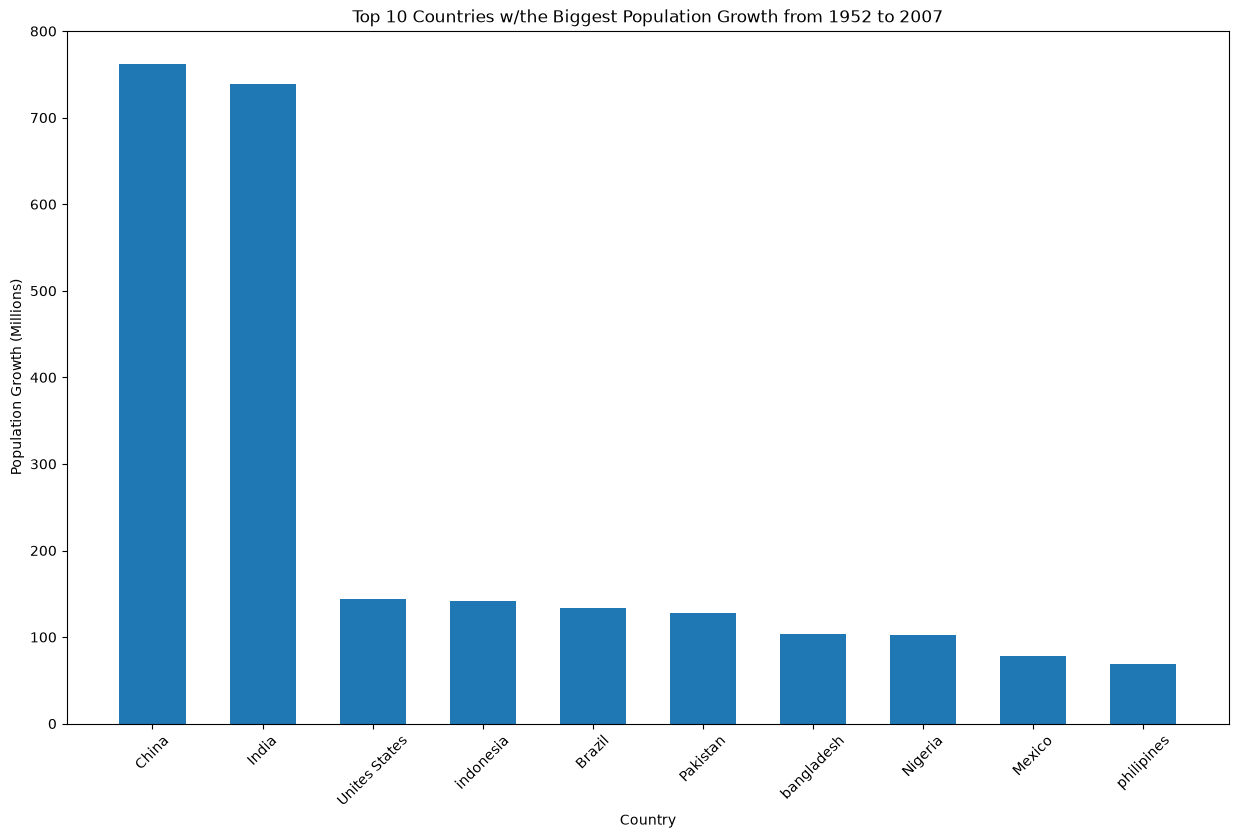

In [16]:
names = [
    'China',
    'India',
    'Unites States',
    'indonesia',
    'Brazil',
    'Pakistan',
    'bangladesh',
    'Nigeria',
    'Mexico',
    'philipines'
]

pop_grow = c_merge['population_growth'] / 10**6

plt.figure(figsize=(15, 9))

plt.bar(names, pop_grow, width=0.6)
plt.xlabel('Country')
plt.ylabel('Population Growth (Millions)')
plt.title(
    'Top 10 Countries w/the Biggest Population Growth from 1952 to 2007'
)

plt.xticks(rotation=45)



In [ ]:
for x,y in zip(names, pop_grow):
    label = "{:.2f}".format(y)

    plt.annotate(
        label,
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

plt.show() 

ConversionError: Failed to convert value(s) to axis units: 'China'

<Figure size 640x480 with 1 Axes>